# [기초-실습] 통계 101×데이터 분석: (1-3장): 통계분석의 기초

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [2]:
# # 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# # 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

In [3]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 기초통계량 계산

**📘 문제**

- 온라인 쇼핑몰 고객 1,000명을 대상으로 1점부터 10점 사이의 만족도 조사를 실시했습니다.
  이 데이터를 바탕으로 고객 만족도의 **중심 경향성**과 **분포 특성**을 파악해 봅시다.

In [6]:
# 데이터 생성
np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

print(df1.head())      
print(df1.shape)       
print(df1.describe()) 

      score
0  7.361415
1  8.601428
2  5.341677
3  6.504867
4  7.348908
(1000, 1)
             score
count  1000.000000
mean      7.428690
std       1.392671
min       2.724405
25%       6.469893
50%       7.421731
75%       8.437992
max      10.000000


**📌 아래를 수행해 보세요:**

- 평균, 중앙값, 최빈값, 표준편차를 계산해 봅시다.
- 히스토그램을 그리고 평균과 중앙값 선으로 표시해 봅시다.
- 데이터의 분포 형태를 해석한 후, 마케팅 전략 수립에 어떻게 활용할 수 있을지 생각해 봅시다.

평균: 7.43
중앙값: 7.42
최빈값(반올림 기준): 7
표준편차: 1.39
왜도: -0.17


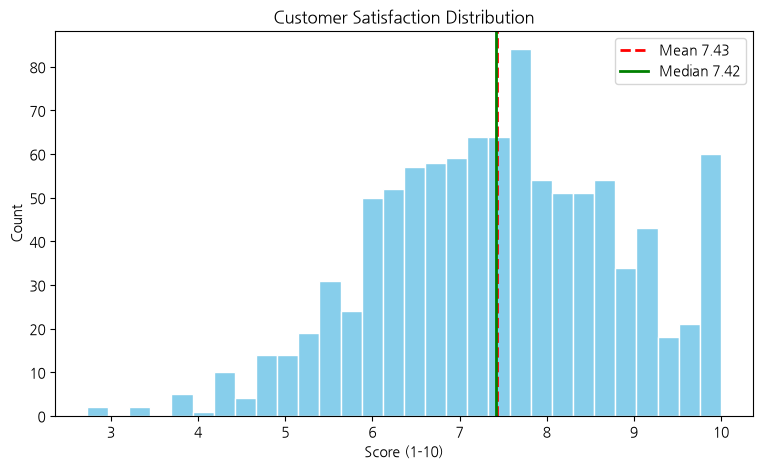

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

# 1. 기술통계량
mean_val   = df1['score'].mean()
median_val = df1['score'].median()
mode_val   = df1['score'].round().mode()[0]   # 반올림 후 최빈값
std_val    = df1['score'].std()

print(f"평균: {mean_val:.2f}")
print(f"중앙값: {median_val:.2f}")
print(f"최빈값(반올림 기준): {mode_val:.0f}")
print(f"표준편차: {std_val:.2f}")
print(f"왜도: {df1['score'].skew():.2f}")

# 2. 히스토그램 + 평균/중앙값 선
plt.figure(figsize=(9, 5))
plt.hist(df1['score'], bins=30, color='skyblue', edgecolor='white')
plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median {median_val:.2f}')
plt.title('Customer Satisfaction Distribution')
plt.xlabel('Score (1-10)')
plt.ylabel('Count')
plt.legend()
plt.show()

In [8]:
rounded = df1['score'].round()
promoter  = (rounded >= 9).mean() * 100
passive   = ((rounded >= 7) & (rounded <= 8)).mean() * 100
detractor = (rounded <= 6).mean() * 100

print(f"추천 고객: {promoter:.1f}%")
print(f"중립 고객: {passive:.1f}%")
print(f"비추천 고객: {detractor:.1f}%")
print(f"NPS 방식 점수: {promoter - detractor:.1f}")

추천 고객: 23.4%
중립 고객: 50.8%
비추천 고객: 25.8%
NPS 방식 점수: -2.4


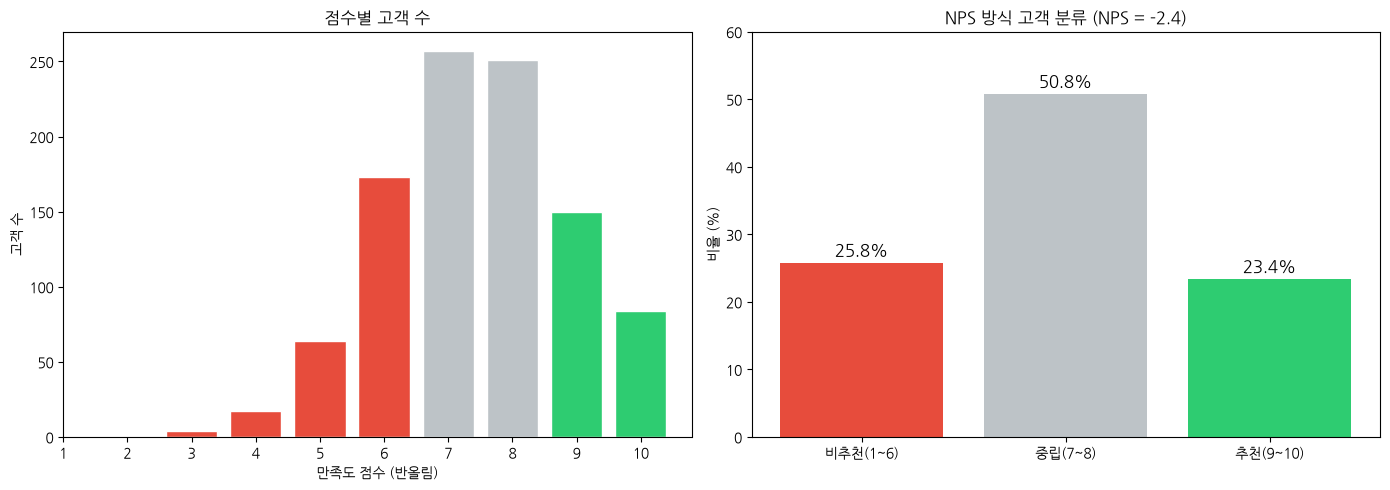

In [9]:
# 그룹 나누기 (반올림 점수 기준)
rounded = df1['score'].round()
df1['group'] = pd.cut(rounded, bins=[0, 6, 8, 10],
                      labels=['비추천(1~6)', '중립(7~8)', '추천(9~10)'])

order = ['비추천(1~6)', '중립(7~8)', '추천(9~10)']
ratio = df1['group'].value_counts(normalize=True).reindex(order) * 100
nps = ratio['추천(9~10)'] - ratio['비추천(1~6)']

colors = ['#e74c3c', '#bdc3c7', '#2ecc71']   # 빨강 / 회색 / 초록

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 왼쪽: 점수별 고객 수 (그룹별 색)
counts = rounded.value_counts().sort_index()
bar_colors = [colors[0] if s <= 6 else colors[1] if s <= 8 else colors[2]
              for s in counts.index]
axes[0].bar(counts.index, counts.values, color=bar_colors, edgecolor='white')
axes[0].set_xticks(range(1, 11))
axes[0].set_title('점수별 고객 수')
axes[0].set_xlabel('만족도 점수 (반올림)')
axes[0].set_ylabel('고객 수')

# 오른쪽: 그룹별 비율 + NPS
bars = axes[1].bar(order, ratio.values, color=colors)
for b, v in zip(bars, ratio.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%',
                 ha='center', fontsize=12)
axes[1].set_ylim(0, 60)
axes[1].set_title(f'NPS 방식 고객 분류 (NPS = {nps:.1f})')
axes[1].set_ylabel('비율 (%)')

plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 평균과 중앙값 사이의 차이는 어느 정도인가요?
   - 두 값이 비슷하다면, 이 데이터는 어떤 분포 형태일 가능성이 있을까요? (예: 대칭형, 정규분포 등)
   - 두 값의 차이가 크다면, 그 이유는 무엇일까요?
   - 어떤 값들이 평균을 끌어내리거나 끌어올렸을까요?

2. 최빈값이 평균보다 낮은 경우, 낮은 점수를 준 고객이 많다는 뜻일 수 있습니다. 이 경우 데이터 분포는 어느 쪽으로 치우쳐 있을까요?
   - 반대로 최빈값이 평균보다 높은 경우에는 어떤 해석이 가능할까요? 이럴 때 분포가 어떻게 달라질 수 있을까요?

3. 이 데이터를 바탕으로 고객 만족도를 높이기 위한 마케팅 전략에는 어떤 것들이 있을까요?

1. 평균(7.43)과 중앙값(7.42)의 차이가 0.01% . 좌우 대칭 잘 맞는 정규분포 형태

2. 반올림한 최빈값(7)이 평균(7.43)보다 낮아 오른쪽 꼬리처럼 보일 수 있다. 하지만 7점(257명)과 8점(251명)이 거의 같아서 생긴 차이이다. 
분포 곡선의 실제 봉우리(7.47)는 평균과 거의 같고 왜도도 -0.17로 0에 가깝다. 따라서 좌우 대칭에 가까운 분포로 판단된다.

3.  온라인 쇼핑몰 고객 1,000명의 만족도(1~10점)조사

## 배경

- 데이터
    - 대상: 온라인 쇼핑몰 고객 1,000명
    - 생성 방식: 평균 7.5, 표준편차 1.5인 정규분포에서 점수를 만든 뒤 1~10점 범위로 자름
    - 특이점: 10점을 넘는 값이 10점으로 묶여, 정확히 10점인 고객이 44명

- 문제 인식
    - 평균은 7.43점으로 높음 → 평균만 보면 "전반적으로 만족"이라는 결론밖에 나오지 않음
    - NPS 방식으로 고객을 나누면 점수는 *-2.4* 로 마이너스

- 분석 방향
    - 고객을 *추천 · 중립 · 비추천* 그룹으로 나누는 NPS 방식으로 적용
    - 그룹별 특징에 맞춰 마케팅 전략을 세움

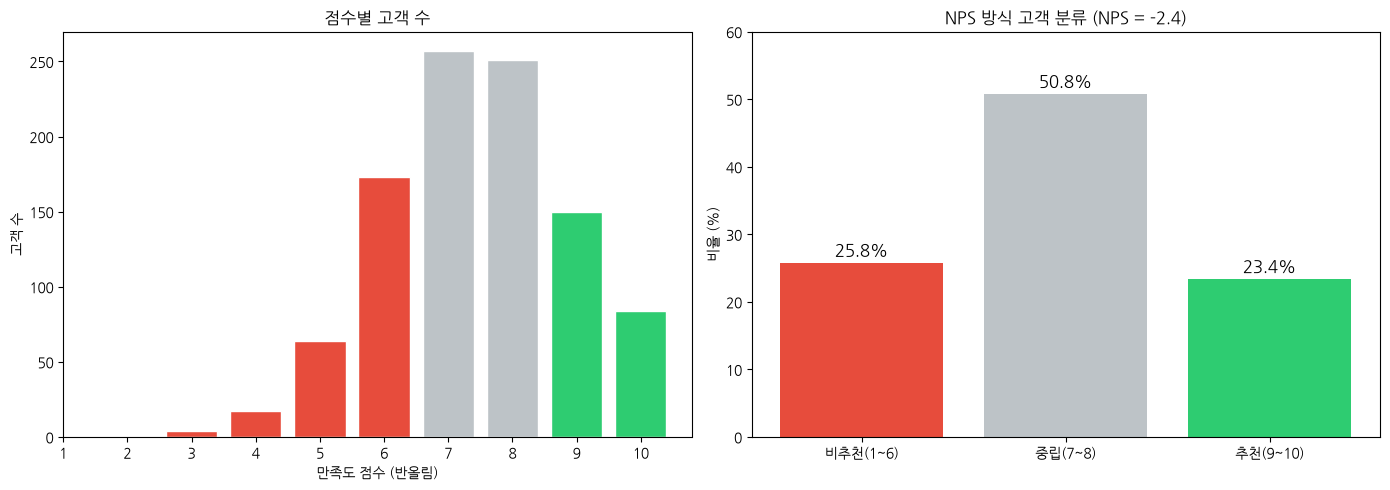
## 그룹별 전략 (우선순위 순)

순위 대상 시도 할 수 있는 액션
1. 비추천 5~6점 (237명)
    불만 제거 → 중립으로 원인 설문, 가장 많은 불만 1~2개 집중 개선, 및 이후 개선 사실 안내
---
2. 중립 7~8점 (508명) 
    감동 추가 → 추천으로 개인화 추천, 멤버십 혜택, 예상보다 좋은 경험(빠른 배송, 샘플 증정)
---
3. 비추천 4점 이하 (21명)
    이탈·악플 방지	1:1 CS 연락, 보상 쿠폰
---
4. 추천 9~10점 (234명)
    입소문 확산	리뷰 이벤트, 친구 추천 보상

##### 결론: 비추천 고객 대부분이 6점에 몰려 있어 회복 가능성이 높음. 핵심 불만을 먼저 제거해 비추천을 줄이고, 절반을 차지하는 중립 고객을 추천 고객으로 끌어올리는 것이 NPS를 높이는 가장 효과적인 전략이다.


# 문제 2. 평균 vs 중앙값 비교

**📘 문제**

- A지역과 B지역의 연봉 데이터를 비교해 봅시다.
- B 지역에는 일부 고소득자가 포함되어 있습니다.

In [13]:
# 데이터 생성
np.random.seed(2025)

# A 지역: 평균 300, 표준편차 50
region_a = np.random.normal(300, 50, 100)

# B 지역: 일반 소득자 + 극단적인 고소득자 포함
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**📌 아래를 수행해 보세요:**

- 각 지역의 평균 연봉과 중앙값을 구해 봅시다.
- 지역별 박스플롯(Boxplot)을 그려서 분포의 차이를 시각적으로 확인해 봅시다.

           평균    중앙값  평균-중앙값 차이
region                         
A       292.5  294.3       -1.8
B       347.6  287.3       60.3


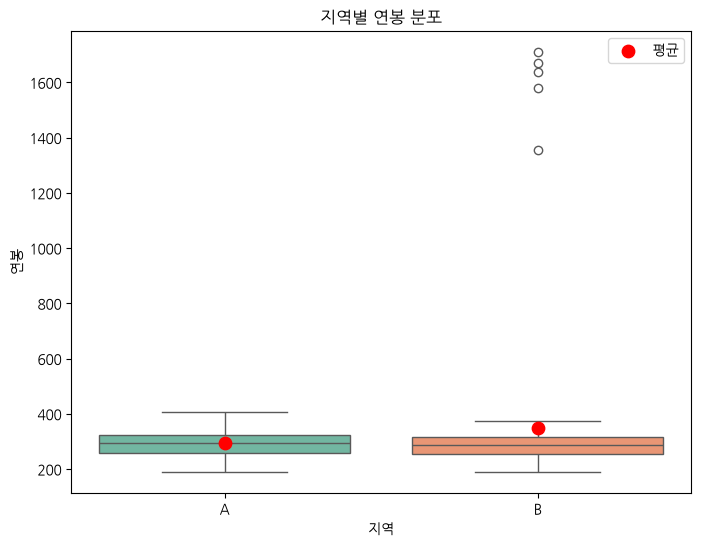

In [14]:
# 데이터 생성
np.random.seed(2025)

region_a = np.random.normal(300, 50, 100)
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})   # ← 빠져 있던 부분

# 1. 지역별 평균과 중앙값
summary = df2.groupby('region')['salary'].agg(['mean', 'median']).round(1)
summary['평균-중앙값 차이'] = (summary['mean'] - summary['median']).round(1)
summary.columns = ['평균', '중앙값', '평균-중앙값 차이']
print(summary)

# 2. 지역별 박스플롯
plt.figure(figsize=(8, 6))
sns.boxplot(data=df2, x='region', y='salary', palette='Set2')

# 평균을 빨간 점으로 표시 (박스 안의 선은 중앙값)
means = df2.groupby('region')['salary'].mean()
plt.scatter([0, 1], means.values, color='red', s=80, zorder=3, label='평균')

plt.title('지역별 연봉 분포')
plt.xlabel('지역')
plt.ylabel('연봉')
plt.legend()
plt.show()

In [19]:
a = df2[df2['region'] == 'A']['salary']   

q1 = a.quantile(0.25)   # 하위 25% 위치의 값
q3 = a.quantile(0.75)   # 하위 75% 위치의 값
iqr = q3 - q1           # 둘의 차이 = IQR

print(q1, q3, iqr)

256.518602699951 322.19658023328356 65.67797753333258


In [ ]:
a = df2[df2['region'] == 'B']['salary']   

q1 = a.quantile(0.25)   # 하위 25% 위치의 값
q3 = a.quantile(0.75)   # 하위 75% 위치의 값
iqr = q3 - q1           # 둘의 차이 = IQR

print(q1, q3, iqr)      

254.21344971323538 314.5291777334101 60.31572802017473


**🧠 데이터를 어떻게 읽을까요?**

1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?
   - 두 지역의 평균 차이가 의미하는 바는 무엇인가요?
   - 고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?

2. 중앙값은 어떠한가요?
   - 평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?
   - 평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?
   - 이상치(Outlier)는 어떻게 표시되나요?
   - 두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?

5. 평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
   - 어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?

## 지역별 연봉 비교

| 지역 | 평균 | 중앙값 | 평균-중앙값 차이 | (IQR) | 이상치 |
| --- | --- | --- | --- | --- | --- |
| A | 292.5 | 294.3 | -1.8 | 65.7 | 0명 |
| B | 347.6 | 287.3 | +60.3 | 60.3 | 5명 |

### 1. 평균 연봉 비교
- B 지역 평균(347.6)이 A 지역(292.5)보다 **55.1 높음**
- 하지만 고소득자 5명을 빼면 B의 평균은 **282.2**로, 오히려 A보다 낮음

### 2. 중앙값 비교
- A(294.3)와 B(287.3)는 비슷하고, B가 약간 낮음

### 3. 극단값의 영향
- 고소득자 5명을 넣었을 때와 뺐을 때 B 지역 값의 변화
	- 평균: 282.2 → 347.6 (**+65.4**)
	- 중앙값: 284.2 → 287.3 (**+3.1**)
- **평균이 극단값에 훨씬 민감함**
	- 평균은 모든 값을 더해서 계산하므로 큰 값 하나가 결과를 크게 바꿈
	- 중앙값은 순서상 가운데 값만 보므로 끝에 있는 값이 커져도 거의 변하지 않음

### 4. 박스플롯 관찰
- 기준: Q3 + 1.5 × IQR 보다 크거나, Q1 − 1.5 × IQR 보다 작은 값
- B 지역에 점 5개(1,354~1,710)가 표시됨 → 고소득자 5명
- A 지역은 이상치 없음
- **IQR**: A- 65.7, B- 60.3으로 거의 비슷함
	- 박스(가운데 50%)만 보면 두 지역의 일반 소득자 분포는 비슷함
	- 두 지역의 차이는 박스 밖의 고소득자 5명에서만 생김

### 5. 평균만 볼 때 생기는 오해
- 평균만 보면 "B 지역 사람들이 연봉을 더 많이 받는다"고 잘못 판단할 수 있음
	- 실제로는 B의 95%가 A와 비슷하거나 약간 낮은 연봉을 받음
- **중앙값이 더 유용한 경우**
	- 소득, 집값, 자산처럼 소수의 매우 큰 값이 있는 데이터
	- 이상치가 있거나 분포가 한쪽으로 치우친 데이터
	- "보통 사람"의 수준을 알고 싶을 때


# 문제 3. 이상값과 분산 비교

**📘 문제**

- 1반과 2반의 시험 점수 분포를 비교해 봅시다.
- 2반에는 극단적인 이상값(예: 부정행위로 0점)이 포함되어 있습니다.

In [22]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**📌 아래를 수행해 보세요:**

1. 각 반의 평균, 표준편차, 최소/최대값을 계산해 봅시다.
2. 박스플롯을 사용하여 두 반의 분포 차이를 시각적으로 비교해 봅시다.
3. 이상값이 통계 지표에 어떤 영향을 주는지 생각해 봅시다.

       mean   std   min    max
class                         
1반     75.7   7.1  60.7   92.2
2반     73.7  22.3   0.0  130.0


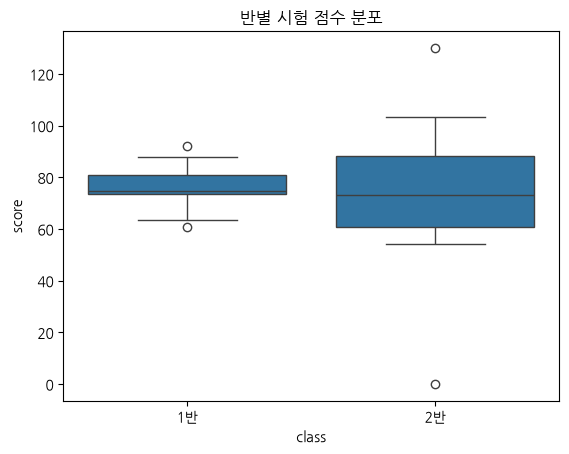

mean    73.3
std     13.8
min     54.1
max     98.3
Name: score, dtype: float64


In [23]:
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

# 1. 통계
print(df3.groupby('class')['score'].agg(['mean', 'std', 'min', 'max']).round(1))

# 2. 박스플롯
sns.boxplot(data=df3, x='class', y='score')
plt.title('반별 시험 점수 분포')
plt.show()

# 3. 이상값 빼고 다시 계산
class2_normal = df3[(df3['class'] == '2반') & (df3['score'].between(1, 100))]['score']
print(class2_normal.agg(['mean', 'std', 'min', 'max']).round(1))

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
   - 점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
   - 이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?
   - 극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
   - 평균과 중앙값의 차이가 의미하는 바는 무엇인가요?

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?
   - 이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
   - 두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?
   - 예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
   - 중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?

### 1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?

| 반 | 표준편차 | 분산 | 범위 (최대-최소) | IQR |
| --- | --- | --- | --- | --- |
| 1반 | 7.1 | 약 50 | 31.5 | 7.5 |
| 2반 | 22.3 | 약 497 | 130.0 | 27.6 |

- **2반의 분산이 약 10배 더 큼**
	- 이유 1: 0점, 130점 같은 극단적인 이상값이 포함됨
	- 이유 2: 이상값을 빼도 2반 표준편차는 14.7로, 원래 점수 차이가 큰 반임
- **퍼짐 정도를 보는 지표**: 표준편차, 분산, 범위, IQR
- **이상값이 포함되면**
	- 표준편차: 14.7 → 22.3으로 커짐
	- 범위: 49.4 → 130.0으로 커짐 (이상값이 곧 최솟값·최댓값이 되기 때문)
	- IQR은 가운데 50%만 보므로 이상값의 영향을 거의 받지 않음

### 2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?

- 2반 평균: 이상값 제외 74.4 → 포함 73.7 (**0.7만 변함**)
	- 0점은 평균을 끌어내리고, 130점은 끌어올림
	- 양쪽 이상값이 서로 **상쇄**되어 평균은 거의 그대로임
- **평균과 중앙값의 차이**
	- 1반: 평균 75.7, 중앙값 74.8 (차이 0.9)
	- 2반: 평균 73.7, 중앙값 73.0 (차이 0.7)
	- 두 반 모두 차이가 작음 → 한쪽으로 치우치지 않은 분포
	- 만약 이상값이 한쪽에만 있었다면 평균과 중앙값의 차이가 크게 벌어졌을 것

### 3. 박스플롯을 통해 이상값은 어떻게 드러나나요?

- **이상값 표시**: 박스와 수염(선) 바깥에 따로 찍힌 **점**
	- 기준: Q1 − 1.5×IQR 보다 작거나, Q3 + 1.5×IQR 보다 큰 값
	- 2반의 0점과 130점이 점으로 표시됨
	- 1반에는 이상값 없음
- **박스 크기 비교**
	- 1반: 박스가 좁음 (IQR 7.5) → 학생들 점수가 고름
	- 2반: 박스가 넓음 (IQR 27.6) → 학생 간 점수 차이가 큼

### 4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?

- 평균만 보면 2반(73.7)이 1반(75.7)보다 2점 낮아 **"2반이 전반적으로 부족하다"** 고 판단할 수 있음
- 하지만 실제로는
	- 2점 차이는 2반 표준편차(22.3)에 비하면 매우 작은 차이
	- 2반의 문제는 "평균이 낮다"가 아니라 **"학생 간 격차가 크다"** 는 것
	- 0점(부정행위)과 130점(입력 오류로 의심)은 실력과 무관한 값
- 따라서 반 전체 수업을 바꾸기보다, **점수가 낮은 학생을 따로 지원**하는 쪽이 맞는 대응임
- **여러 지표를 함께 봐야 하는 이유**
	- 평균: 이상값이 양쪽에 있으면 문제를 숨김
	- 중앙값: 이상값에 흔들리지 않는 "보통 학생" 수준을 보여줌
	- 표준편차: 반 안의 격차를 보여줌
	- 박스플롯: 이상값을 눈으로 바로 찾아줌

# 문제 4. IQR 이상값 제거

**📘 문제**

- 앞의 문제에서 2반에는 **극단적인 이상값(예: 매우 낮은 점수)**이 포함되어 있어
  통계 지표, 특히 평균에 큰 영향을 주는 것을 확인했습니다.
- 이번에는 **IQR(사분위 범위)**을 기준으로 이상값을 제거한 뒤, 이상값 제거 전후의 평균을 비교해 봅시다

<br>

**📌 아래를 수행해 보세요:**

- 2반의 점수 데이터를 대상으로 IQR 기준을 사용해 이상값을 판별하고 제거해 봅시다.
- 이상값 제거 전과 제거 후의 평균을 각각 계산해 봅시다.
- 이상값 제거가 평균에 어떤 영향을 주는지 설명해 봅시다.
- 필요하다면 중앙값과도 비교해 봅시다.

In [24]:
# 2반 점수만 꺼내기
class2_scores = df3[df3['class'] == '2반']['score']

# 1. IQR 기준으로 이상값 판별
q1 = class2_scores.quantile(0.25)
q3 = class2_scores.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print(f"Q1: {q1:.1f}, Q3: {q3:.1f}, IQR: {iqr:.1f}")
print(f"정상 범위: {lower:.1f} ~ {upper:.1f}")

outliers = class2_scores[(class2_scores < lower) | (class2_scores > upper)]
print(f"이상값: {outliers.round(1).tolist()}")

# 이상값 제거
class2_clean = class2_scores[(class2_scores >= lower) & (class2_scores <= upper)]
print(f"제거 전 {len(class2_scores)}명 → 제거 후 {len(class2_clean)}명")

# 2. 제거 전/후 비교 (평균, 중앙값, 표준편차)
compare = pd.DataFrame({
    '제거 전': [class2_scores.mean(), class2_scores.median(), class2_scores.std()],
    '제거 후': [class2_clean.mean(), class2_clean.median(), class2_clean.std()]
}, index=['평균', '중앙값', '표준편차']).round(1)
compare['변화'] = (compare['제거 후'] - compare['제거 전']).round(1)
print(compare)

Q1: 60.8, Q3: 88.4, IQR: 27.6
정상 범위: 19.3 ~ 129.8
이상값: [0.0, 130.0]
제거 전 30명 → 제거 후 28명
      제거 전  제거 후   변화
평균    73.7  74.4  0.7
중앙값   73.0  73.0  0.0
표준편차  22.3  14.7 -7.6


**🧠 데이터를 어떻게 읽을까요?**

1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
   - 평균이 중앙값에 가까워졌나요?
   - 이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?

2. 왜 IQR을 기준으로 이상값을 판단할까요?
   - IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
   - 평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?

3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
   - 분석 목적에 따라 이상값은 중요한 정보가 될 수 있습니다.

4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
   - 이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
   - 두 지표를 함께 보면 어떤 장점이 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 4] 여기에 의견을 작성해주세요.

# 문제 5. 변수 유형 분류

**📘 문제**

- 아래 데이터에서 변수의 유형(연속형, 범주형, 이산형 등)을 구분해 봅시다.
- 변수의 의미를 고려하여 어떤 분석 방식이 적절한지도 함께 생각해 봅시다.

In [ ]:
# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

**📌 아래를 수행해 보세요:**

1. 각 변수의 데이터 타입을 확인해 봅시다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.
   - 연속형 (numeric-continuous)
   - 이산형 (numeric-discrete)
   - 범주형 (categorical)
   - 서열형 범주 (ordinal-categorical)

In [ ]:
# 아래를 수행해 보세요:
# [문제 5] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 5] 여기에 의견을 작성해주세요.

# 문제 6. 상관관계 분석

**📘 문제**

- 이번에는 변수들 간의 **관계(상관관계)**를 분석해 봅시다.
- 특히 기온(`temp`), 습도(`humidity`), 판매(`sales`) 변수 간의 관계를 수치와 시각화로 살펴보겠습니다.

In [ ]:
# 데이터 생성
np.random.seed(202)

temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200

df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

**📌 아래를 수행해 보세요:**

1. 아래의 기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.

2. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 6] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 상관계수 행렬을 보고,
   - 어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
   - 어느 쌍이 **양의 상관관계**, 어느 쌍이 **음의 상관관계**인가요?

2. 페어플롯에서
   - 어떤 변수 쌍은 **직선 형태**로 관계가 보이나요?
   - 어떤 변수 쌍은 **분산이 크거나 패턴이 없는**가요?

3. **상관관계가 반드시 인과관계를 의미하지는 않습니다.**
   - 온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?

4. 이 데이터를 바탕으로 어떤 **추가 가설**이나 **실험 설계**를 생각해볼 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 6] 여기에 의견을 작성해주세요.

# 문제 7. 범주형 변수 시각화

**📘 문제**

- 앞에서는 수치형 변수의 분포를 시각화하고, 변수 간의 관계도 살펴보았습니다.
- 이번에는 범주형 변수인 커피 음료 데이터를 시각화해 봅시다.
- 어떤 종류가 많이 판매되었는지 빈도 분석을 통해 알아보겠습니다.

In [ ]:
# 데이터 생성
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
   - 각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
   - **막대그래프(bar plot)**를 그려서 결과를 시각화해 봅시다.

2. 시각화 결과를 보고,
   - 어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
   - 이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 7] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
   - 판매량이 가장 많은 음료는?
   - 그 다음으로 인기 있는 음료는?

2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
   - 가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
   - 판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?

3. 막대그래프는 왜 범주형 변수에 적합할까요?
   - `drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?

4. 범주형 변수 분석 시 주의할 점은?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 7] 여기에 의견을 작성해주세요.

# 문제 8. 요일별 평균 비교

**📘 문제**

- 이번에는 요일 별 소비 금액 데이터를 분석해 봅시다.
- 각 요일마다 평균 소비 금액이 얼마나 되는지 비교하고,
  **평일과 주말의 소비 패턴 차이**도 함께 살펴보겠습니다.

In [ ]:
# 데이터 생성
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
2. 요일별 평균 금액을 **막대그래프(bar plot)**로 시각화해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 8] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 요일에 소비 금액이 가장 높나요?
   - 주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?

2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?

3. 이 결과를 어떻게 활용할 수 있을까요?
   - 주말에 더 많은 재고를 준비하거나
   - 평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?

---

> 💬 정리해 보기
>
> - 범주형 변수(요일)별로 연속형 변수(소비 금액)의 평균을 비교하면 소비 패턴을 이해하고 전략을 수립하는 데 유용한 인사이트를 얻을 수 있습니다.

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 8] 여기에 의견을 작성해주세요.

# 문제 9. 정규분포와 표준편차

**📘 문제**

- 정규분포와 표준편차의 개념을 실제 데이터에 적용해 보겠습니다.
- 정규분포를 따르는 점수 데이터에서 다음을 확인해 봅시다:
  - 평균 ±1σ, 평균 ±2σ 범위에 속한 값들의 비율은 실제로 얼마나 되는가?
  - 이 결과가 이론적인 68-95-99 법칙과 얼마나 유사한지 비교해 봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 9] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
3. 표준편차는 왜 중요한 지표인가요?
4. 이 개념이 실제로 어떻게 활용될 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 9] 여기에 의견을 작성해주세요.

# 문제 10. 표본 평균 실험

**📘 문제**

- 큰 모집단에서 표본을 여러 번 추출하여 표본 평균의 분포를 비교해봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다:
   - 표본 크기 5
   - 표본 크기 50
3. 두 조건의 **표본 평균 분포(histogram)**를 비교합니다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 10] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. **표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?**
2. **왜 표본 크기가 중요할까요?**
3. **이 개념은 실제로 어디에 활용될 수 있을까요?**

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 10] 여기에 의견을 작성해주세요.

# 문제 11. 단순 선형 회귀 분석

**📘 문제**

- 공부 시간과 성적 간의 관계를 회귀 분석으로 확인해봅시다.

In [ ]:
# 데이터 생성
from sklearn.linear_model import LinearRegression

np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

**📌 아래를 수행해 보세요:**

1. 공부 시간(`study_time`)과 성적(`score`)간의 관계를 단순 선형 회귀모델로 분석합니다.
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
3. 산점도 위에 회귀선을 시각화해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 11] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 공부 시간이 성적에 어떤 영향을 주었나요?
2. 회귀선은 데이터를 잘 설명하고 있나요?
3. 이 회귀식을 현실에 적용할 수 있을까요?
4. 선형 회귀분석은 언제 활용할 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 11] 여기에 의견을 작성해주세요.

# 문제 12. A/B 테스트 해석

**📘 문제**

- 두 그룹의 전환율 차이를 계산하고 해석해봅시다.

In [ ]:
# 데이터 생성
np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

**📌 아래를 수행해 보세요:**

1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.

In [ ]:
# 아래를 수행해 보세요:
# [문제 12] 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

1. 두 그룹의 전환율 차이는 얼마나 되나요?
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
4. A/B 테스트는 현실에서 어떻게 쓰일까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 12] 여기에 의견을 작성해주세요.